In [1]:
import joblib

rf_model = joblib.load("saved_models/random_forest.pkl")
dt_model = joblib.load("saved_models/decision_tree.pkl")
lr_model = joblib.load("saved_models/logistic_regression.pkl")

scaler = joblib.load("saved_models/scaler.pkl")
label_encoder = joblib.load("saved_models/label_encoder.pkl")
feature_names = joblib.load("saved_models/feature_names.pkl")

print("Models loaded successfully!")

Models loaded successfully!


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from lime.lime_tabular import LimeTabularExplainer

df = pd.read_csv("netguard_selected_features.csv")

X = df.drop("Label", axis=1)
y = label_encoder.transform(df["Label"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset loaded successfully!")
print("Features:", X_train.shape[1])

Dataset loaded successfully!
Features: 20


In [3]:
explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=X_train.columns.tolist(),
    class_names=label_encoder.classes_.tolist(),
    mode="classification"
)

print("LIME explainer created successfully!")

LIME explainer created successfully!


In [4]:
sample_index = 0

sample = X_test.iloc[sample_index]

prediction = rf_model.predict(sample.to_frame().T)[0]

print("Actual class:", label_encoder.inverse_transform(
    [y_test[sample_index]]
)[0])

print("Predicted class:", label_encoder.inverse_transform(
    [prediction]
)[0])

Actual class: BENIGN
Predicted class: BENIGN


In [15]:
predicted_class = int(rf_model.predict(sample.to_frame().T)[0])

explanation = explainer.explain_instance(
    data_row=sample.to_numpy(),
    predict_fn=rf_model.predict_proba,
    labels=(predicted_class,),
    num_features=10
)


d:\Network_Traffic_Threat_Analysis\venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [14]:
print("Label encoder classes:", label_encoder.classes_)
print("Random Forest class order:", rf_model.classes_)
print("Predicted class:", predicted_class)

Label encoder classes: ['BENIGN' 'DDoS']
Random Forest class order: [0 1]
Predicted class: 0


In [9]:
explanation = explainer.explain_instance(
    data_row=sample.to_numpy(),
    predict_fn=rf_model.predict_proba,
    num_features=20
)



d:\Network_Traffic_Threat_Analysis\venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


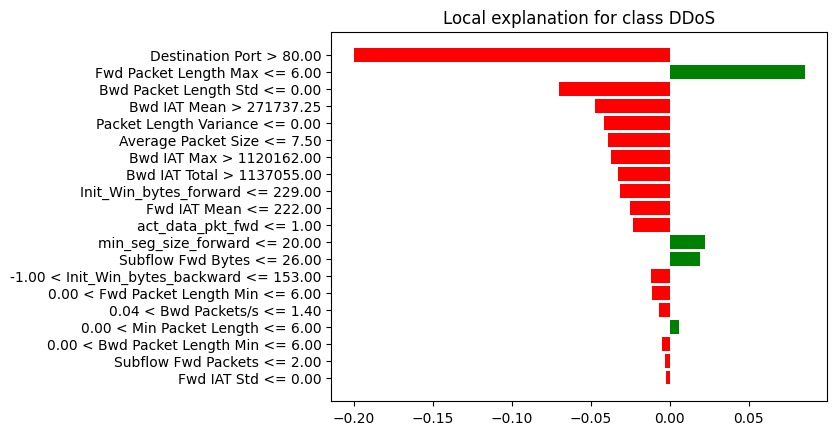

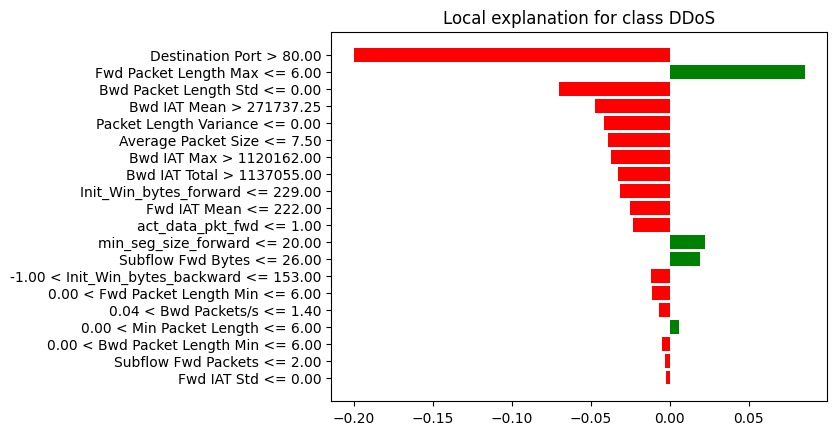

In [10]:
explanation.as_pyplot_figure()

In [ ]:
y_pred_rf = selected_model.predict(X_test_lime)

for class_id, class_name in enumerate(label_encoder.classes_):

    candidates = np.where(
        (y_test == class_id) &
        (y_pred_rf == class_id)
    )[0]

    if len(candidates) == 0:
        print(f"No correctly classified {class_name} sample found.")
        continue

    idx = candidates[0]
    row = X_test_lime.iloc[idx]

    exp = explainer.explain_instance(
        data_row=row.to_numpy(),
        predict_fn=selected_model.predict_proba,
        labels=[class_id],
        num_features=10,
        num_samples=5000
    )

    print(f"\nActual and predicted class: {class_name}")
    print("Test sample index:", idx)

    fig = exp.as_pyplot_figure(label=class_id)
    plt.title(f"Random Forest — {class_name} Explanation")
    plt.tight_layout()
    plt.show()